In [7]:
import torch

print("PyTorch Version:", torch.__version__)
print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

PyTorch Version: 2.14.1+cu130
GPU Available: True
GPU Name: Tesla T4


**Google Drive Setup**

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Checking Dataset ZIP File**

In [9]:
import os

dataset_folder = '/content/drive/MyDrive/Neem_Leaf_Dataset'

print("Files in Dataset Folder:")
print(os.listdir(dataset_folder))

Files in Dataset Folder:
['Azadirachta Indica Leaf Dataset V1.zip']


**Extracting the Dataset**

In [10]:
import zipfile
import os

zip_path = '/content/drive/MyDrive/Neem_Leaf_Dataset/Azadirachta Indica Leaf Dataset V1.zip'

extract_path = '/content/Neem_Leaf_Dataset'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print(os.listdir(extract_path))

Dataset extracted successfully!
['Azadirachta Indica Leaf Dataset V1']


**Exploring Dataset Structure**

In [11]:
import os

base_path = '/content/Neem_Leaf_Dataset/Azadirachta Indica Leaf Dataset V1'

for root, dirs, files in os.walk(base_path):
    level = root.replace(base_path, '').count(os.sep)

    if level <= 2:
        print('  ' * level + os.path.basename(root) + '/')

Azadirachta Indica Leaf Dataset V1/
  Validation/
    Disease/
    Chlorotic/
    Healthy/
  Train/
    Disease/
    Chlorotic/
    Healthy/
  Test/
    Disease/
    Chlorotic/
    Healthy/


**Counting Dataset Images**

In [12]:
import os

classes = ['Healthy', 'Chlorotic', 'Disease']
splits = ['Train', 'Validation', 'Test']

total_images = 0

for split in splits:
    print(f"\n{split} Dataset:")

    split_total = 0

    for class_name in classes:
        folder = os.path.join(base_path, split, class_name)

        image_count = len([
            f for f in os.listdir(folder)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ])

        print(f"{class_name}: {image_count}")

        split_total += image_count

    print(f"Total {split}: {split_total}")
    total_images += split_total

print(f"\nTotal Images in Dataset: {total_images}")


Train Dataset:
Healthy: 1000
Chlorotic: 1000
Disease: 1000
Total Train: 3000

Validation Dataset:
Healthy: 150
Chlorotic: 150
Disease: 150
Total Validation: 450

Test Dataset:
Healthy: 150
Chlorotic: 150
Disease: 150
Total Test: 450

Total Images in Dataset: 3900


**Importing Required Libraries**

In [13]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

from PIL import Image, ImageOps
import matplotlib.pyplot as plt
import numpy as np
import os

**Visualizing Original Images**

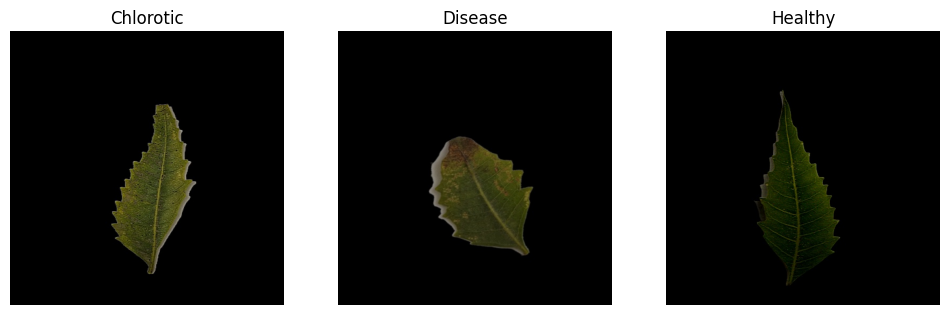

In [14]:
import matplotlib.pyplot as plt
from PIL import Image
import os

classes = ['Chlorotic', 'Disease', 'Healthy']

plt.figure(figsize=(12, 4))

for i, class_name in enumerate(classes):

    folder = os.path.join(base_path, 'Train', class_name)

    image_name = os.listdir(folder)[0]
    image_path = os.path.join(folder, image_name)

    img = Image.open(image_path)

    plt.subplot(1, 3, i+1)
    plt.imshow(img)
    plt.title(class_name)
    plt.axis('off')

plt.show()

**Checking Original Image Dimensions**

In [15]:
from PIL import Image
import os

classes = ['Healthy', 'Chlorotic', 'Disease']
splits = ['Train', 'Validation', 'Test']

for split in splits:
    print(f"\n{split} Dataset:")

    for class_name in classes:

        folder = os.path.join(base_path, split, class_name)

        image_name = os.listdir(folder)[0]
        image_path = os.path.join(folder, image_name)

        img = Image.open(image_path)

        print(class_name, ":", img.size)


Train Dataset:
Healthy : (512, 512)
Chlorotic : (512, 512)
Disease : (512, 512)

Validation Dataset:
Healthy : (512, 384)
Chlorotic : (512, 384)
Disease : (512, 384)

Test Dataset:
Healthy : (512, 384)
Chlorotic : (512, 384)
Disease : (512, 384)


**Image Preprocessing**

In [16]:
train_transform = transforms.Compose([
    transforms.Lambda(
        lambda img: ImageOps.pad(
            img, (224, 224), color=(0, 0, 0)
        )
    ),
    transforms.ToTensor()
])

val_transform = transforms.Compose([
    transforms.Lambda(
        lambda img: ImageOps.pad(
            img, (224, 224), color=(0, 0, 0)
        )
    ),
    transforms.ToTensor()
])

test_transform = transforms.Compose([
    transforms.Lambda(
        lambda img: ImageOps.pad(
            img, (224, 224), color=(0, 0, 0)
        )
    ),
    transforms.ToTensor()
])

**Visualizing Preprocessed Images**

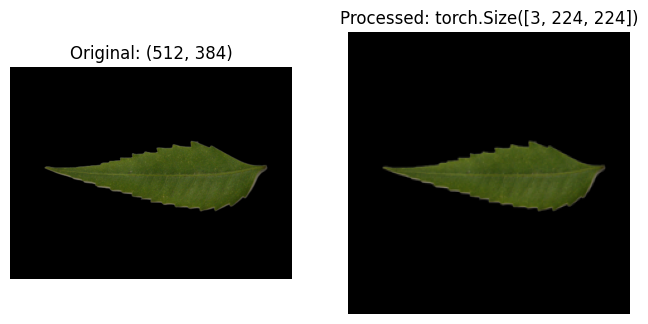

In [17]:
import matplotlib.pyplot as plt
from PIL import Image
import os

image_path = os.path.join(
    base_path, 'Validation', 'Healthy',
    os.listdir(os.path.join(base_path, 'Validation', 'Healthy'))[0]
)

original_img = Image.open(image_path).convert('RGB')

processed_img = val_transform(original_img)

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(original_img)
plt.title(f"Original: {original_img.size}")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(processed_img.permute(1, 2, 0))
plt.title(f"Processed: {processed_img.shape}")
plt.axis('off')

plt.show()

**Loading the Datasets**

In [18]:
from torchvision import datasets

train_data = datasets.ImageFolder(
    root=os.path.join(base_path, 'Train'),
    transform=train_transform
)

val_data = datasets.ImageFolder(
    root=os.path.join(base_path, 'Validation'),
    transform=val_transform
)

test_data = datasets.ImageFolder(
    root=os.path.join(base_path, 'Test'),
    transform=test_transform
)

print("Training Images:", len(train_data))
print("Validation Images:", len(val_data))
print("Testing Images:", len(test_data))

print("Classes:", train_data.classes)
print("Class to Index:", train_data.class_to_idx)

Training Images: 3000
Validation Images: 450
Testing Images: 450
Classes: ['Chlorotic', 'Disease', 'Healthy']
Class to Index: {'Chlorotic': 0, 'Disease': 1, 'Healthy': 2}


**Creating DataLoaders**

In [19]:
from torch.utils.data import DataLoader

batch_size = 32

train_loader = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_data,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=False
)

print("Training Batches:", len(train_loader))
print("Validation Batches:", len(val_loader))
print("Testing Batches:", len(test_loader))

Training Batches: 94
Validation Batches: 15
Testing Batches: 15


**Checking Available Device**

In [20]:
import torch

device = 'cuda' if torch.cuda.is_available() else 'cpu'

print("Available Device:", device)

if device == 'cuda':
    print("GPU Name:", torch.cuda.get_device_name(0))

Available Device: cuda
GPU Name: Tesla T4


**Building the CNN Model**

In [21]:
import torch.nn as nn

class CNNModel(nn.Module):

    def __init__(self, num_classes=3):
        super(CNNModel, self).__init__()

        # Convolutional Layers
        self.conv_layers = nn.Sequential(

            nn.Conv2d(3, 32, kernel_size=3, padding=1),  # 224x224
            nn.ReLU(),
            nn.MaxPool2d(2),  # 112x112

            nn.Conv2d(32, 64, kernel_size=3, padding=1),  # 112x112
            nn.ReLU(),
            nn.MaxPool2d(2),  # 56x56

            nn.Conv2d(64, 128, kernel_size=3, padding=1),  # 56x56
            nn.ReLU(),
            nn.MaxPool2d(2),  # 28x28

            nn.Conv2d(128, 256, kernel_size=3, padding=1),  # 28x28
            nn.ReLU(),
            nn.MaxPool2d(2),  # 14x14

        )

        # Fully Connected Layers
        self.fc_layers = nn.Sequential(

            nn.Flatten(),

            nn.Linear(256 * 14 * 14, 512),
            nn.ReLU(),

            nn.Dropout(0.5),

            nn.Linear(512, num_classes)

        )

    def forward(self, x):

        x = self.conv_layers(x)
        x = self.fc_layers(x)

        return x

**Initializing the CNN Model**

In [22]:
model = CNNModel(num_classes=3).to(device)

print(model)

CNNModel(
  (conv_layers): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc_layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=50176, out_features=512, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=512, out_features=3, bias=True)
  )
)

**Counting Trainable Parameters**

In [23]:
total_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Total Trainable Parameters:", total_params)

Total Trainable Parameters: 26080579


**Defining Loss Function and Optimizer**

In [24]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

**Setting Training Configuration**

In [25]:
num_epochs = 25
best_val_loss = float('inf')
print("Number of Epochs:", num_epochs)
print("Batch Size:", batch_size)
print("Learning Rate:", 0.001)
print("Device:", device)

Number of Epochs: 25
Batch Size: 32
Learning Rate: 0.001
Device: cuda


**Training and Validation**

In [26]:
train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

**Training the CNN Model**

In [27]:
for epoch in range(num_epochs):

    # Training
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_train_loss = running_loss / len(train_loader)
    epoch_train_accuracy = 100 * correct / total

    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_accuracy)

    # Validation
    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item()

            _, predicted = torch.max(outputs.data, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    epoch_val_loss = val_running_loss / len(val_loader)
    epoch_val_accuracy = 100 * val_correct / val_total

    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_accuracy)

    if epoch_val_loss < best_val_loss:
       best_val_loss = epoch_val_loss
       torch.save(model.state_dict(), "/content/drive/MyDrive/Neem_Leaf_Dataset/best_cnn_model_baseline.pth")
       print("Best model saved!")

    print(f"Epoch [{epoch+1}/{num_epochs}]")
    print(f"Train Loss: {epoch_train_loss:.4f} | Train Accuracy: {epoch_train_accuracy:.2f}%")
    print(f"Val Loss: {epoch_val_loss:.4f} | Val Accuracy: {epoch_val_accuracy:.2f}%")
    print("-" * 50)

Best model saved!
Epoch [1/25]
Train Loss: 0.9744 | Train Accuracy: 52.73%
Val Loss: 0.7557 | Val Accuracy: 70.44%
--------------------------------------------------
Best model saved!
Epoch [2/25]
Train Loss: 0.7492 | Train Accuracy: 66.33%
Val Loss: 0.6019 | Val Accuracy: 74.44%
--------------------------------------------------
Best model saved!
Epoch [3/25]
Train Loss: 0.6469 | Train Accuracy: 71.80%
Val Loss: 0.5263 | Val Accuracy: 78.44%
--------------------------------------------------
Best model saved!
Epoch [4/25]
Train Loss: 0.5910 | Train Accuracy: 73.43%
Val Loss: 0.4615 | Val Accuracy: 79.11%
--------------------------------------------------
Epoch [5/25]
Train Loss: 0.5512 | Train Accuracy: 75.73%
Val Loss: 0.4651 | Val Accuracy: 80.22%
--------------------------------------------------
Epoch [6/25]
Train Loss: 0.5579 | Train Accuracy: 75.37%
Val Loss: 0.4782 | Val Accuracy: 78.22%
--------------------------------------------------
Best model saved!
Epoch [7/25]
Train Los

**Training and Validation Graph**

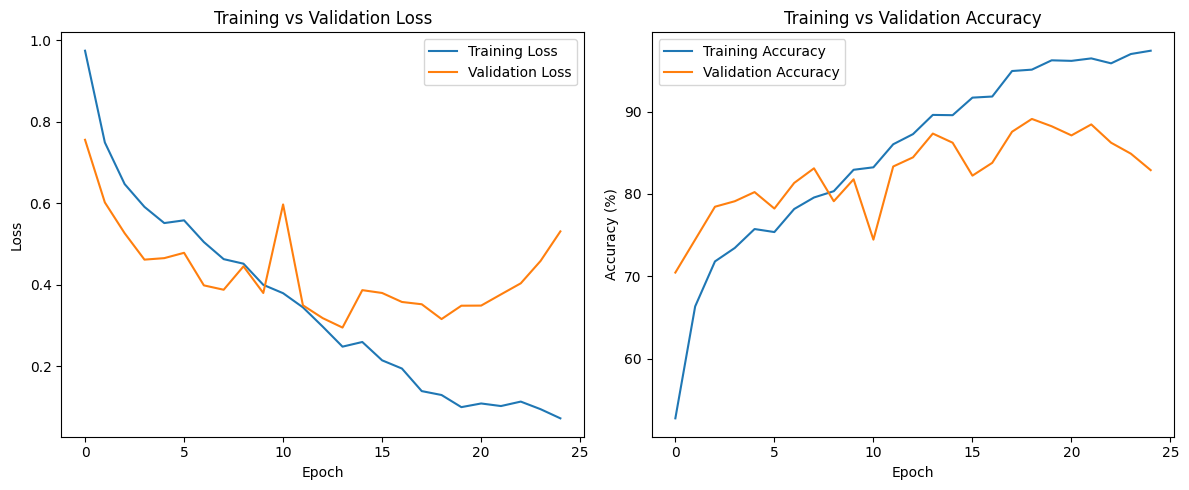

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Loss Graph
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()

# Accuracy Graph
plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label='Training Accuracy')
plt.plot(val_accuracies, label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('Training vs Validation Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

**Load Best Model**

In [29]:
model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/Neem_Leaf_Dataset/best_cnn_model_baseline.pth",
        map_location=device
    )
)

model.eval()

print("Best Baseline Model Loaded Successfully!")

Best Baseline Model Loaded Successfully!


**Model Evaluation on Test Dataset**

In [30]:
model.eval()

test_correct = 0
test_total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs.data, 1)

        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

test_accuracy = 100 * test_correct / test_total

print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Accuracy: 87.33%


**Confusion Matrix and Classification Report**

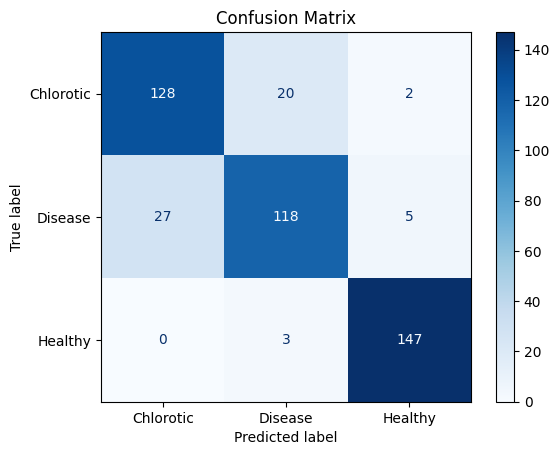

Classification Report:

              precision    recall  f1-score   support

   Chlorotic       0.83      0.85      0.84       150
     Disease       0.84      0.79      0.81       150
     Healthy       0.95      0.98      0.97       150

    accuracy                           0.87       450
   macro avg       0.87      0.87      0.87       450
weighted avg       0.87      0.87      0.87       450



In [31]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import torch

model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predicted.cpu().numpy())

# Confusion Matrix
cm = confusion_matrix(all_labels, all_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=test_data.classes
)

disp.plot(cmap='Blues', values_format='d')

plt.title("Confusion Matrix")
plt.show()

# Classification Report
print("Classification Report:\n")

print(classification_report(
    all_labels,
    all_predictions,
    target_names=test_data.classes
))

**Augmentation in training dataset**

In [32]:
from torchvision import transforms
from PIL import ImageOps

train_transform = transforms.Compose([

    # Resize and preserve aspect ratio
    transforms.Lambda(
        lambda img: ImageOps.pad(
            img, (224, 224), color=(0, 0, 0)
        )
    ),

    # Geometric Augmentation
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(
        degrees=10,
        fill=0
    ),

    # Mild Color Augmentation
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10
    ),

    transforms.ToTensor()
])

**Recreate Training Dataset**

In [33]:
train_data = datasets.ImageFolder(
    root=base_path + '/Train',
    transform=train_transform
)

train_loader = DataLoader(
    train_data,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

print("Training Images:", len(train_data))
print("Training Batches:", len(train_loader))


Training Images: 3000
Training Batches: 94


**Initialize a New CNN Model**

In [34]:
model = CNNModel(num_classes=3).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)
print("New CNN Model Initialized Successfully!")


New CNN Model Initialized Successfully!


**Training History Reset**

In [35]:
train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []


**Train the Augmented CNN Model**

In [36]:
for epoch in range(num_epochs):

    # Training
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_train_loss = running_loss / len(train_loader)
    epoch_train_accuracy = 100 * correct / total

    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_accuracy)

    # Validation
    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item()

            _, predicted = torch.max(outputs.data, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    epoch_val_loss = val_running_loss / len(val_loader)
    epoch_val_accuracy = 100 * val_correct / val_total

    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_accuracy)

    if epoch_val_loss < best_val_loss:
       best_val_loss = epoch_val_loss

       torch.save(
            model.state_dict(),
            "/content/drive/MyDrive/Neem_Leaf_Dataset/best_cnn_model_augmented.pth"
            )
       print("Best augmented model saved!")

    print(f"Epoch [{epoch+1}/{num_epochs}]")
    print(f"Train Loss: {epoch_train_loss:.4f} | Train Accuracy: {epoch_train_accuracy:.2f}%")
    print(f"Val Loss: {epoch_val_loss:.4f} | Val Accuracy: {epoch_val_accuracy:.2f}%")
    print("-" * 50)


Epoch [1/25]
Train Loss: 1.0043 | Train Accuracy: 47.30%
Val Loss: 0.6715 | Val Accuracy: 73.56%
--------------------------------------------------
Epoch [2/25]
Train Loss: 0.6701 | Train Accuracy: 70.23%
Val Loss: 0.5306 | Val Accuracy: 77.11%
--------------------------------------------------
Epoch [3/25]
Train Loss: 0.5988 | Train Accuracy: 74.07%
Val Loss: 0.4589 | Val Accuracy: 78.22%
--------------------------------------------------
Epoch [4/25]
Train Loss: 0.5544 | Train Accuracy: 75.17%
Val Loss: 0.5065 | Val Accuracy: 76.67%
--------------------------------------------------
Epoch [5/25]
Train Loss: 0.5550 | Train Accuracy: 75.60%
Val Loss: 0.4893 | Val Accuracy: 75.33%
--------------------------------------------------
Epoch [6/25]
Train Loss: 0.5198 | Train Accuracy: 77.00%
Val Loss: 0.3942 | Val Accuracy: 80.44%
--------------------------------------------------
Epoch [7/25]
Train Loss: 0.5114 | Train Accuracy: 77.30%
Val Loss: 0.4071 | Val Accuracy: 82.22%
---------------

***Loading the Best Augmented Model***

In [37]:
model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/Neem_Leaf_Dataset/best_cnn_model_augmented.pth",
        map_location=device
    )
)

model.eval()

print("Best Augmented Model Loaded Successfully!")

Best Augmented Model Loaded Successfully!


**Test Dataset Evaluation**

In [38]:
model.eval()

test_correct = 0
test_total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs.data, 1)

        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

test_accuracy = 100 * test_correct / test_total

print(f"Test Accuracy: {test_accuracy:.2f}%")


Test Accuracy: 92.89%


**Updated Confusion Matrix and Classification Report**

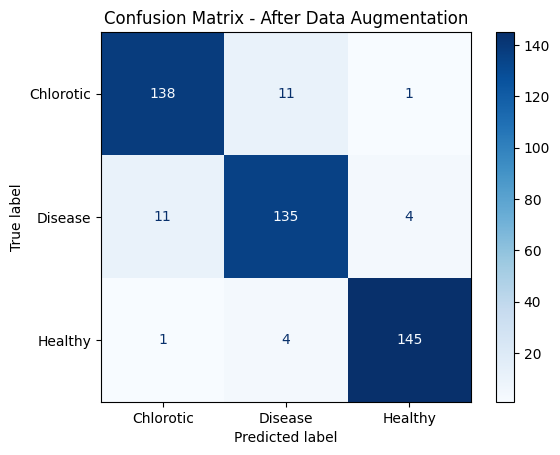

Classification Report - After Data Augmentation:

              precision    recall  f1-score   support

   Chlorotic       0.92      0.92      0.92       150
     Disease       0.90      0.90      0.90       150
     Healthy       0.97      0.97      0.97       150

    accuracy                           0.93       450
   macro avg       0.93      0.93      0.93       450
weighted avg       0.93      0.93      0.93       450



In [39]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import torch

model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predicted.cpu().numpy())


# Confusion Matrix
cm = confusion_matrix(all_labels, all_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=test_data.classes
)

disp.plot(cmap='Blues', values_format='d')
plt.title("Confusion Matrix - After Data Augmentation")
plt.show()


# Classification Report
print("Classification Report - After Data Augmentation:\n")

print(classification_report(
    all_labels,
    all_predictions,
    target_names=test_data.classes
))


**Before vs After Comparison Graph**

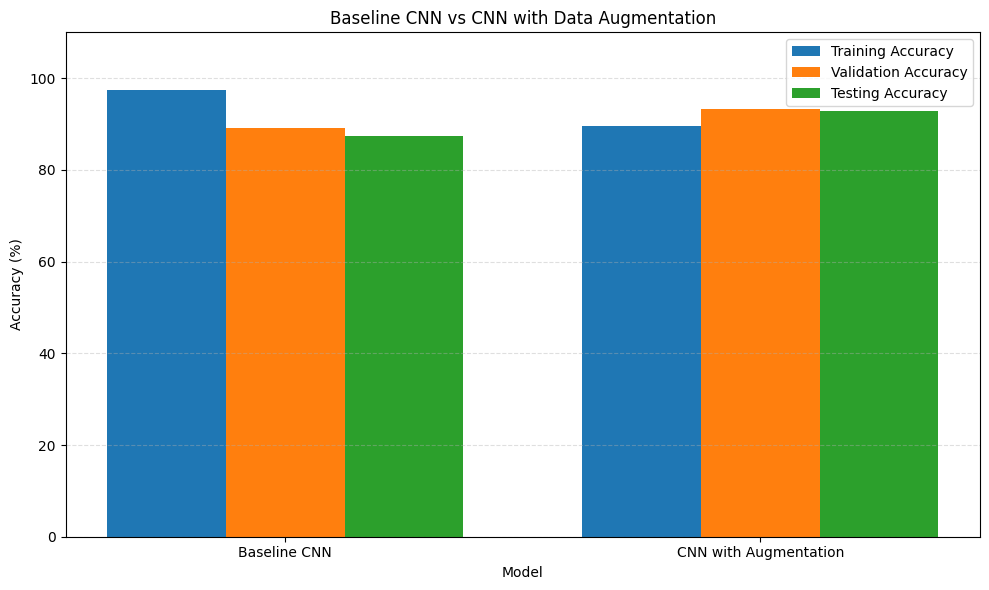

In [44]:
import numpy as np
import matplotlib.pyplot as plt

models = ['Baseline CNN', 'CNN with Augmentation']

train_acc = [97.40, 89.50]
val_acc = [89.11, 93.33]
test_acc = [87.33, 92.89]

x = np.arange(len(models))
width = 0.25

plt.figure(figsize=(10, 6))

plt.bar(x - width, train_acc, width, label='Training Accuracy')
plt.bar(x, val_acc, width, label='Validation Accuracy')
plt.bar(x + width, test_acc, width, label='Testing Accuracy')

plt.xlabel('Model')
plt.ylabel('Accuracy (%)')
plt.title('Baseline CNN vs CNN with Data Augmentation')
plt.xticks(x, models)
plt.ylim(0, 110)

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

**Save trained CNN model**

In [45]:
torch.save(model.state_dict(), 'neem_leaf_cnn_augmented.pth')

print("Augmented CNN model saved successfully!")

class_names = train_data.classes
print("Classes:", class_names)

Augmented CNN model saved successfully!
Classes: ['Chlorotic', 'Disease', 'Healthy']


**Summary**

In [46]:

baseline_test_accuracy = 87.33
augmented_test_accuracy = 92.89

baseline_best_val_loss = 0.2947
augmented_best_val_loss = 0.1608

baseline_best_epoch = 14
augmented_best_epoch = 23

print("========== FINAL CNN RESULTS ==========")

print("\nDataset: Neem Leaf Dataset")
print("Number of Classes:", len(class_names))
print("Training Images:", len(train_data))
print("Validation Images:", len(val_data))
print("Testing Images:", len(test_data))

print("\nBefore Data Augmentation (Baseline CNN)")
print(f"Test Accuracy: {baseline_test_accuracy:.2f}%")
print(f"Best Validation Loss: {baseline_best_val_loss:.4f}")
print(f"Best Epoch: {baseline_best_epoch}")

print("\nAfter Data Augmentation (Augmented CNN)")
print(f"Test Accuracy: {augmented_test_accuracy:.2f}%")
print(f"Best Validation Loss: {augmented_best_val_loss:.4f}")
print(f"Best Epoch: {augmented_best_epoch}")

improvement = augmented_test_accuracy - baseline_test_accuracy

print(f"\nAccuracy Improvement: {improvement:+.2f} percentage points")

print("\n========================================")


========== FINAL CNN RESULTS ==========

Dataset: Neem Leaf Dataset
Number of Classes: 3
Training Images: 3000
Validation Images: 450
Testing Images: 450

Before Data Augmentation (Baseline CNN)
Test Accuracy: 87.33%
Best Validation Loss: 0.2947
Best Epoch: 14

After Data Augmentation (Augmented CNN)
Test Accuracy: 92.89%
Best Validation Loss: 0.1608
Best Epoch: 23

Accuracy Improvement: +5.56 percentage points

